## Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import cv2

from sklearn.preprocessing import minmax_scale
import os

## Preprocess

In [ ]:
df = pd.read_csv('./data/train.csv')
df

,id,class,segmentation
0,case123_day20_slice_0001,large_bowel,NaN
1,case123_day20_slice_0001,small_bowel,NaN
2,case123_day20_slice_0001,stomach,NaN
3,case123_day20_slice_0002,large_bowel,NaN
4,case123_day20_slice_0002,small_bowel,NaN
...,...,...,...
115483,case30_day0_slice_0143,small_bowel,NaN
115484,case30_day0_slice_0143,stomach,NaN
115485,case30_day0_slice_0144,large_bowel,NaN
115486,case30_day0_slice_0144,small_bowel,NaN


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115488 entries, 0 to 115487
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            115488 non-null  object
 1   class         115488 non-null  object
 2   segmentation  33913 non-null   object
dtypes: object(3)
memory usage: 2.6+ MB


In [96]:
df.describe()

,id,class,segmentation
count,115488,115488,33913
unique,38496,3,33899
top,case123_day20_slice_0001,large_bowel,12629 10 12894 12 13158 15 13423 17 13688 19 1...
freq,3,38496,2


In [97]:
df.dropna(inplace=True)

In [98]:
df[df['segmentation'].duplicated(keep=False)]

,id,class,segmentation
3259,case133_day25_slice_0079,small_bowel,29755 2 30112 8 30468 14 30826 17 31185 19 315...
3262,case133_day25_slice_0080,small_bowel,29755 2 30112 8 30468 14 30826 17 31185 19 315...
3638,case133_day23_slice_0061,stomach,34757 14 35114 19 35473 21 35831 23 36189 26 3...
3641,case133_day23_slice_0062,stomach,34757 14 35114 19 35473 21 35831 23 36189 26 3...
13134,case15_day20_slice_0059,large_bowel,28436 5 28701 7 28966 8 29232 9 29498 9 29765 ...
13137,case15_day20_slice_0060,large_bowel,28436 5 28701 7 28966 8 29232 9 29498 9 29765 ...
24745,case115_day0_slice_0105,small_bowel,16389 4 16648 15 16889 2 16913 24 17153 6 1717...
24748,case115_day0_slice_0106,small_bowel,16389 4 16648 15 16889 2 16913 24 17153 6 1717...
24751,case115_day0_slice_0107,small_bowel,16091 1 16114 4 16355 6 16379 8 16620 8 16644 ...
24754,case115_day0_slice_0108,small_bowel,16091 1 16114 4 16355 6 16379 8 16620 8 16644 ...


In [99]:
df.drop_duplicates(inplace=True)

In [100]:
def add_required_columns(id):
    address = id.split('_')
    source = f'train/{address[0]}/{address[0]}_{address[1]}/scans'
    for filename in os.listdir(source):
        if filename.startswith(f'slice_{address[3]}'):
            return int(address[0][4:]), int(address[1][3:]), int(address[3]), int(filename[:-4].split('_')[2]), int(filename[:-4].split('_')[3]), source + '/' + filename

In [101]:
df[['case', 'day', 'slice', 'width', 'height', 'path']] = df['id'].apply(add_required_columns).apply(pd.Series)
df

,id,class,segmentation,case,day,slice,width,height,path
194,case123_day20_slice_0065,stomach,28094 3 28358 7 28623 9 28889 9 29155 9 29421 ...,123,20,65,266,266,train/case123/case123_day20/scans/slice_0065_2...
197,case123_day20_slice_0066,stomach,27561 8 27825 11 28090 13 28355 14 28620 15 28...,123,20,66,266,266,train/case123/case123_day20/scans/slice_0066_2...
200,case123_day20_slice_0067,stomach,15323 4 15587 8 15852 10 16117 11 16383 12 166...,123,20,67,266,266,train/case123/case123_day20/scans/slice_0067_2...
203,case123_day20_slice_0068,stomach,14792 5 15056 9 15321 11 15587 11 15852 13 161...,123,20,68,266,266,train/case123/case123_day20/scans/slice_0068_2...
206,case123_day20_slice_0069,stomach,14526 6 14789 12 15054 14 15319 16 15584 17 15...,123,20,69,266,266,train/case123/case123_day20/scans/slice_0069_2...
...,...,...,...,...,...,...,...,...,...
115459,case30_day0_slice_0135,small_bowel,22540 1 22804 5 23069 7 23334 10 23600 11 2386...,30,0,135,266,266,train/case30/case30_day0/scans/slice_0135_266_...
115461,case30_day0_slice_0136,large_bowel,18746 7 19009 23 19038 7 19273 44 19537 49 198...,30,0,136,266,266,train/case30/case30_day0/scans/slice_0136_266_...
115462,case30_day0_slice_0136,small_bowel,23079 1 23343 6 23608 9 23874 11 24139 13 2440...,30,0,136,266,266,train/case30/case30_day0/scans/slice_0136_266_...
115464,case30_day0_slice_0137,large_bowel,18746 2 19010 8 19040 3 19274 25 19302 12 1953...,30,0,137,266,266,train/case30/case30_day0/scans/slice_0137_266_...


In [102]:
df2 = df.pivot_table(index='id', columns='class', values='segmentation', aggfunc='first')
df2.reset_index(inplace=True)
df2

class,id,large_bowel,small_bowel,stomach
0,case101_day20_slice_0066,NaN,NaN,32107 5 32371 10 32635 13 32900 15 33165 17 33...
1,case101_day20_slice_0067,NaN,NaN,31313 2 31577 7 31841 10 32105 14 32369 17 326...
2,case101_day20_slice_0068,NaN,NaN,30517 2 30781 6 31046 9 31311 11 31575 15 3184...
3,case101_day20_slice_0069,NaN,NaN,29981 10 30246 13 30511 16 30776 19 31041 21 3...
4,case101_day20_slice_0070,NaN,NaN,28918 9 29182 14 29446 18 29711 21 29976 23 30...
...,...,...,...,...
16585,case9_day22_slice_0115,38022 2 38380 7 38739 9 39099 10 39295 6 39459...,21360 7 21718 10 22077 12 22435 15 22788 1 227...,NaN
16586,case9_day22_slice_0116,38021 4 38379 8 38739 10 38938 2 39099 10 3929...,21361 3 21718 9 22076 12 22435 14 22794 17 231...,NaN
16587,case9_day22_slice_0117,38020 7 38379 10 38738 12 38936 4 39098 12 392...,21717 8 22076 11 22434 15 22791 20 23149 25 23...,NaN
16588,case9_day22_slice_0118,37661 5 38019 10 38378 12 38738 12 39097 14 39...,21359 6 21717 10 22074 15 22431 20 22790 23 23...,NaN


In [103]:
df3 = df.merge(df2, on='id')
df3.drop(columns=['class', 'segmentation'], inplace=True)
df3.drop_duplicates(inplace=True)
df3

,id,case,day,slice,width,height,path,large_bowel,small_bowel,stomach
0,case123_day20_slice_0065,123,20,65,266,266,train/case123/case123_day20/scans/slice_0065_2...,NaN,NaN,28094 3 28358 7 28623 9 28889 9 29155 9 29421 ...
1,case123_day20_slice_0066,123,20,66,266,266,train/case123/case123_day20/scans/slice_0066_2...,NaN,NaN,27561 8 27825 11 28090 13 28355 14 28620 15 28...
2,case123_day20_slice_0067,123,20,67,266,266,train/case123/case123_day20/scans/slice_0067_2...,NaN,NaN,15323 4 15587 8 15852 10 16117 11 16383 12 166...
3,case123_day20_slice_0068,123,20,68,266,266,train/case123/case123_day20/scans/slice_0068_2...,NaN,NaN,14792 5 15056 9 15321 11 15587 11 15852 13 161...
4,case123_day20_slice_0069,123,20,69,266,266,train/case123/case123_day20/scans/slice_0069_2...,NaN,NaN,14526 6 14789 12 15054 14 15319 16 15584 17 15...
...,...,...,...,...,...,...,...,...,...,...
33903,case30_day0_slice_0133,30,0,133,266,266,train/case30/case30_day0/scans/slice_0133_266_...,17695 8 17957 23 18213 39 18477 45 18741 52 19...,23337 15 23601 20 23866 23 24131 25 24396 27 2...,NaN
33905,case30_day0_slice_0134,30,0,134,266,266,train/case30/case30_day0/scans/slice_0134_266_...,17694 5 17957 10 18215 2 18219 17 18478 32 187...,23336 13 23601 16 23867 18 24132 20 24398 21 2...,NaN
33907,case30_day0_slice_0135,30,0,135,266,266,train/case30/case30_day0/scans/slice_0135_266_...,17957 1 18219 10 18482 16 18744 23 19008 43 19...,22540 1 22804 5 23069 7 23334 10 23600 11 2386...,NaN
33909,case30_day0_slice_0136,30,0,136,266,266,train/case30/case30_day0/scans/slice_0136_266_...,18746 7 19009 23 19038 7 19273 44 19537 49 198...,23079 1 23343 6 23608 9 23874 11 24139 13 2440...,NaN


### Create Sets

In [ ]:
with open('./splits/train.txt', 'r') as file:
    train_cases = file.read().replace('case', '').split('\n')
train_cases = [int(num) for num in train_cases]

with open('./splits/valid.txt', 'r') as file:
    valid_cases = file.read().replace('case', '').split('\n')
valid_cases = [int(num) for num in valid_cases]

with open('./splits/test.txt', 'r') as file:
    test_cases = file.read().replace('case', '').split('\n')
test_cases = [int(num) for num in test_cases]

In [105]:
train_df = df3[df3['case'].isin(train_cases)]
valid_df = df3[df3['case'].isin(valid_cases)]
test_df = df3[df3['case'].isin(test_cases)]

In [ ]:
train_df.to_csv('./splits_data/train_df.csv', index=False)
valid_df.to_csv('./splits_data/valid_df.csv', index=False)
test_df.to_csv('./splits_data/test_df.csv', index=False)

In [107]:
train_df

,id,case,day,slice,width,height,path,large_bowel,small_bowel,stomach
1048,case129_day20_slice_0047,129,20,47,360,310,train/case129/case129_day20/scans/slice_0047_3...,54203 2 54559 8 54918 10 55277 12 55636 13 559...,NaN,60663 4 61021 8 61379 11 61737 14 62095 16 624...
1050,case129_day20_slice_0048,129,20,48,360,310,train/case129/case129_day20/scans/slice_0048_3...,52760 4 53118 8 53477 10 53836 13 54196 14 545...,NaN,59224 7 59581 11 59939 14 60298 16 60656 19 61...
1052,case129_day20_slice_0049,129,20,49,360,310,train/case129/case129_day20/scans/slice_0049_3...,52039 5 52397 9 52756 12 53115 14 53474 16 538...,NaN,56695 8 57052 14 57411 17 57770 19 58129 21 58...
1054,case129_day20_slice_0050,129,20,50,360,310,train/case129/case129_day20/scans/slice_0050_3...,50959 13 51316 18 51675 20 52034 21 52393 23 5...,NaN,57053 14 57411 18 57770 21 58129 24 58488 26 5...
1056,case129_day20_slice_0051,129,20,51,360,310,train/case129/case129_day20/scans/slice_0051_3...,49528 2 49886 6 50244 9 50594 20 50953 22 5131...,NaN,56694 14 57052 19 57411 21 57770 24 58129 26 5...
...,...,...,...,...,...,...,...,...,...,...
33903,case30_day0_slice_0133,30,0,133,266,266,train/case30/case30_day0/scans/slice_0133_266_...,17695 8 17957 23 18213 39 18477 45 18741 52 19...,23337 15 23601 20 23866 23 24131 25 24396 27 2...,NaN
33905,case30_day0_slice_0134,30,0,134,266,266,train/case30/case30_day0/scans/slice_0134_266_...,17694 5 17957 10 18215 2 18219 17 18478 32 187...,23336 13 23601 16 23867 18 24132 20 24398 21 2...,NaN
33907,case30_day0_slice_0135,30,0,135,266,266,train/case30/case30_day0/scans/slice_0135_266_...,17957 1 18219 10 18482 16 18744 23 19008 43 19...,22540 1 22804 5 23069 7 23334 10 23600 11 2386...,NaN
33909,case30_day0_slice_0136,30,0,136,266,266,train/case30/case30_day0/scans/slice_0136_266_...,18746 7 19009 23 19038 7 19273 44 19537 49 198...,23079 1 23343 6 23608 9 23874 11 24139 13 2440...,NaN


## Plots

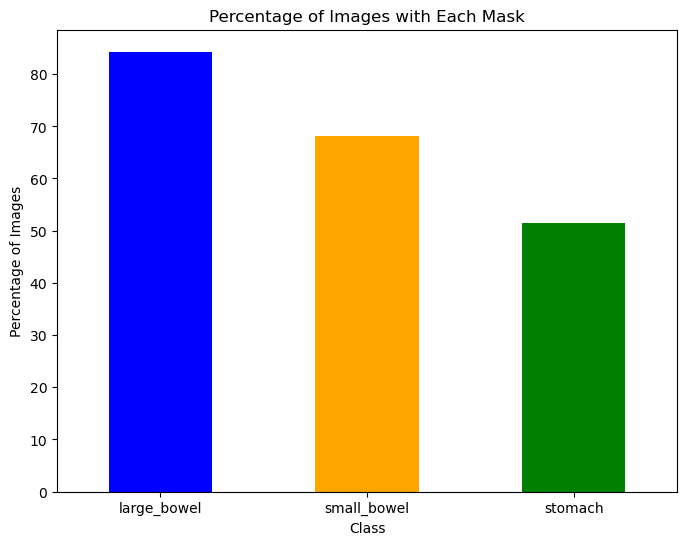

In [108]:
plt.figure(figsize=(8,6))

presence_df = train_df.iloc[:, 7:].notna()

class_counts = presence_df.sum()
total_images = len(train_df)
class_percentages = (class_counts / total_images) * 100

class_percentages.plot(kind='bar', color=['blue', 'orange', 'green'])
plt.xlabel('Class')
plt.ylabel('Percentage of Images')
plt.title('Percentage of Images with Each Mask')
plt.xticks(rotation=0)
plt.show()

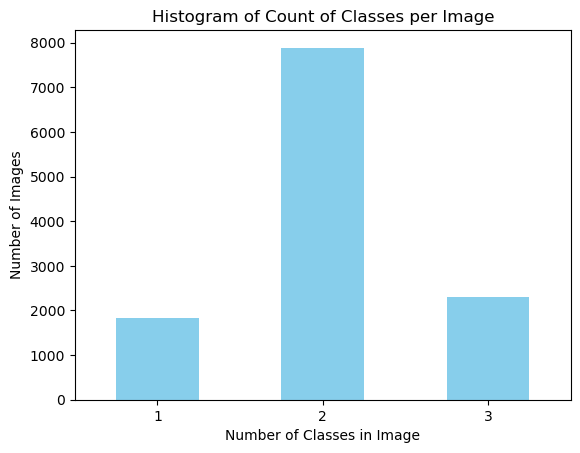

In [109]:
class_counts_per_image = presence_df.sum(axis=1)

class_count_frequencies = class_counts_per_image.value_counts().sort_index()

class_count_frequencies.plot(kind='bar', color='skyblue')
plt.xlabel('Number of Classes in Image')
plt.ylabel('Number of Images')
plt.title('Histogram of Count of Classes per Image')
plt.xticks(rotation=0)
plt.show()

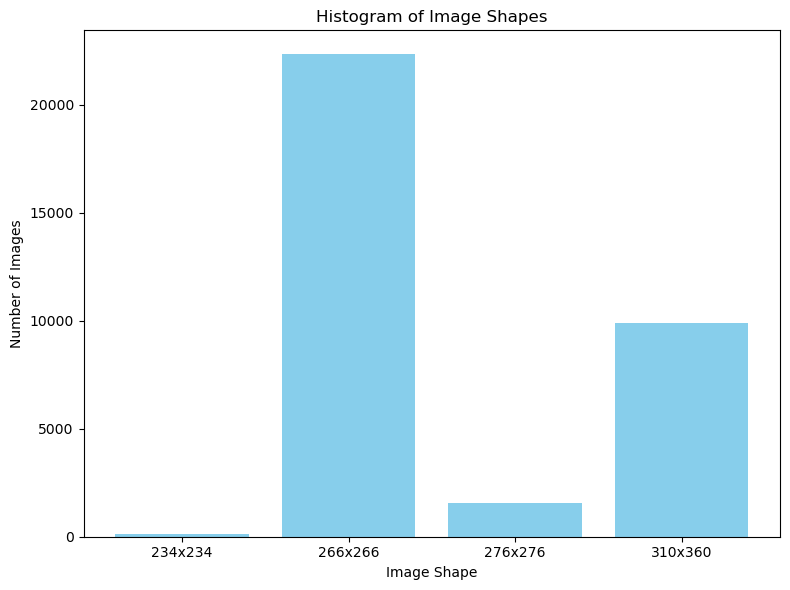

In [ ]:
image_shapes = df.groupby(['height', 'width']).size().reset_index(name='count')

plt.figure(figsize=(8, 6))
plt.bar(image_shapes.apply(lambda x: f"{x['height']}x{x['width']}", axis=1), image_shapes['count'],  color='skyblue')
plt.xlabel('Image Shape')
plt.ylabel('Number of Images')
plt.title('Histogram of Image Shapes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Visualize Samples

In [175]:
def rle2mask(rle, shape):
    rle_list = rle.split(' ')
    rle_list = np.array(rle_list, dtype=np.uint32)
    starts = rle_list[::2] - 1 #make the range start from 0
    lengths = rle_list[1::2]
    mask = np.zeros(shape[0] * shape[1])
    for s,l in zip(starts,lengths):
        mask[s:s+l] = 1
    return mask.reshape(shape)


def masks(df, row, sample):
    masks = np.zeros((3, sample.shape[0], sample.shape[1]))
    if pd.notna(df.iloc[row]['stomach']):
        masks[0, :, :] = rle2mask(df.iloc[row]['stomach'], sample.shape)
    
    if pd.notna(df.iloc[row]['large_bowel']):
        masks[1, :, :] = rle2mask(df.iloc[row]['large_bowel'], sample.shape)
    
    if pd.notna(df.iloc[row]['small_bowel']):
        masks[2, :, :] = rle2mask(df.iloc[row]['small_bowel'], sample.shape)
    
    return masks
    
    
def show_image_with_mask(row, df):
    sample = cv2.imread(df.iloc[row]['path'], cv2.IMREAD_UNCHANGED)
    scaled_smaple = minmax_scale(sample)
    plt.figure(figsize=(16,8))
    plt.subplot(1,3,1)
    plt.title('Original Image')
    plt.axis('off')
    plt.imshow(scaled_smaple, cmap='gray')

    mask = masks(df, row, sample).transpose((1,2,0))
    plt.subplot(1,3,2)
    plt.title('Masks')
    handles = [Rectangle((0,0),0,1, color=c) for c in [(1, 0, 0), (0, 1, 0), (0, 0, 1)]]
    labels = ["Stomach", "Large Bowel", "Small Bowel"]
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(mask)

    plt.subplot(1,3,3)
    plt.title('Image with Masks')
    handles = [Rectangle((0,0),1,1, color=c) for c in [(1, 0, 0, 0.8), (0, 1, 0, 0.8), (0, 0, 1, 0.8)]]
    labels = ["Stomach", "Large Bowel", "Small Bowel"]
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(scaled_smaple, cmap='gray')
    plt.imshow(mask, alpha=0.45)

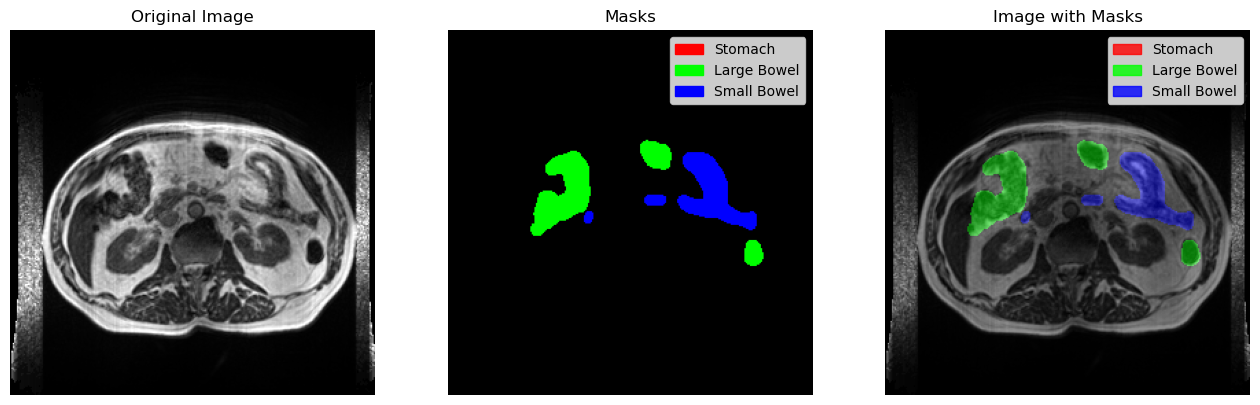

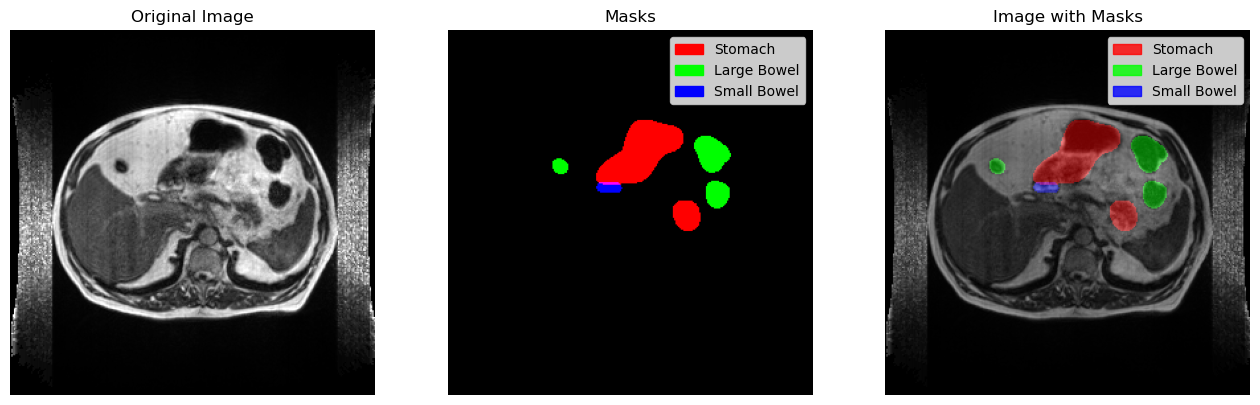

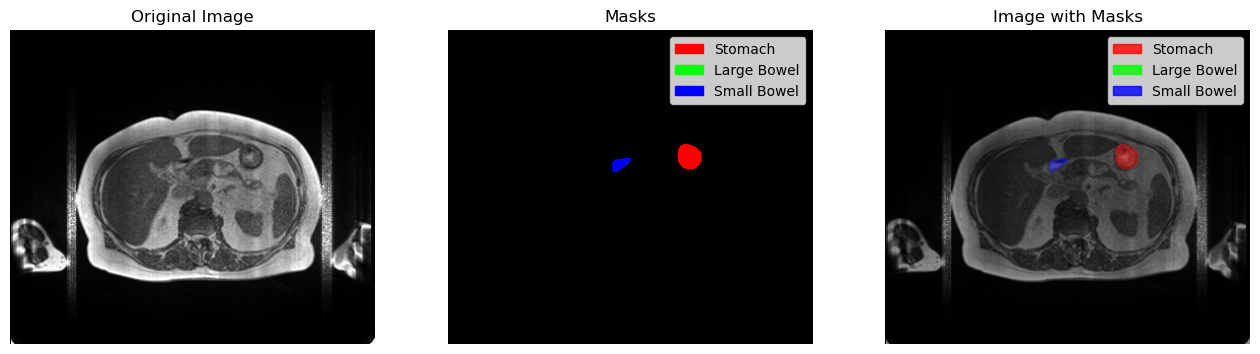

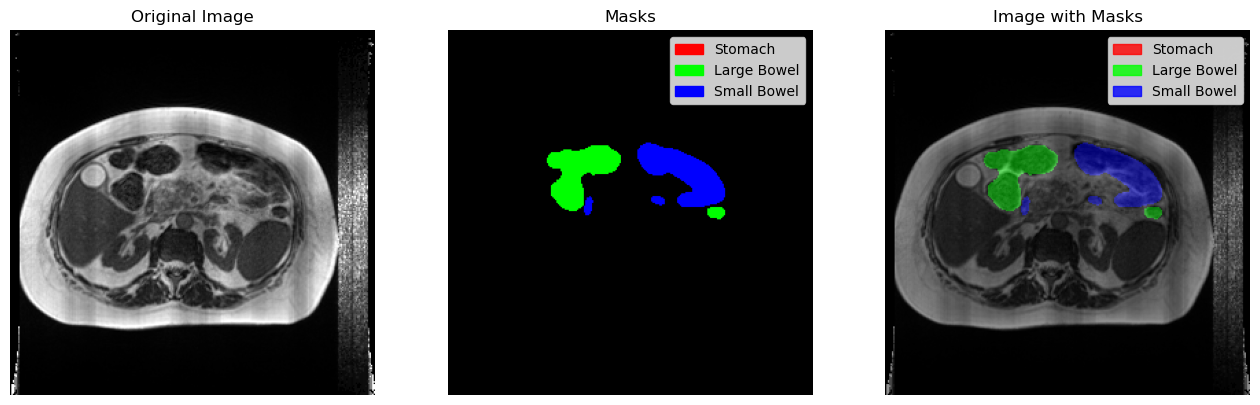

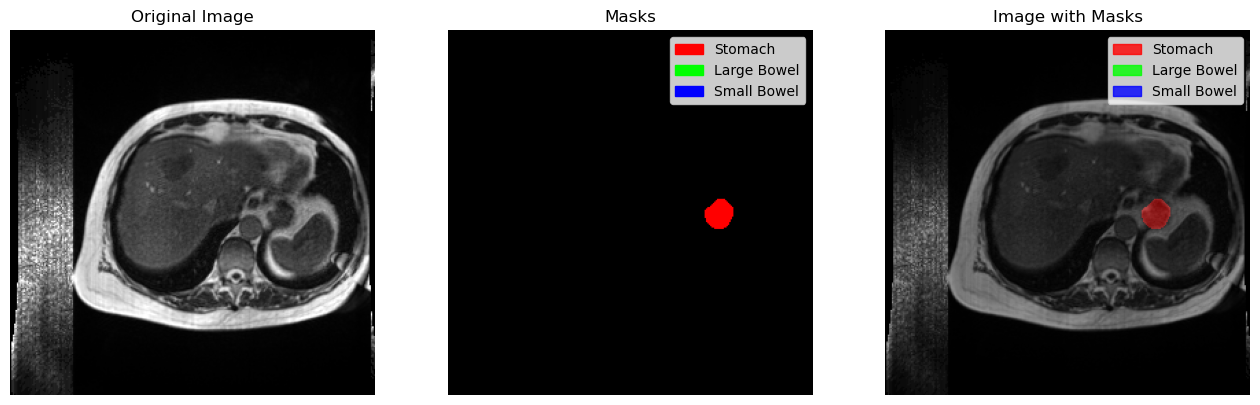

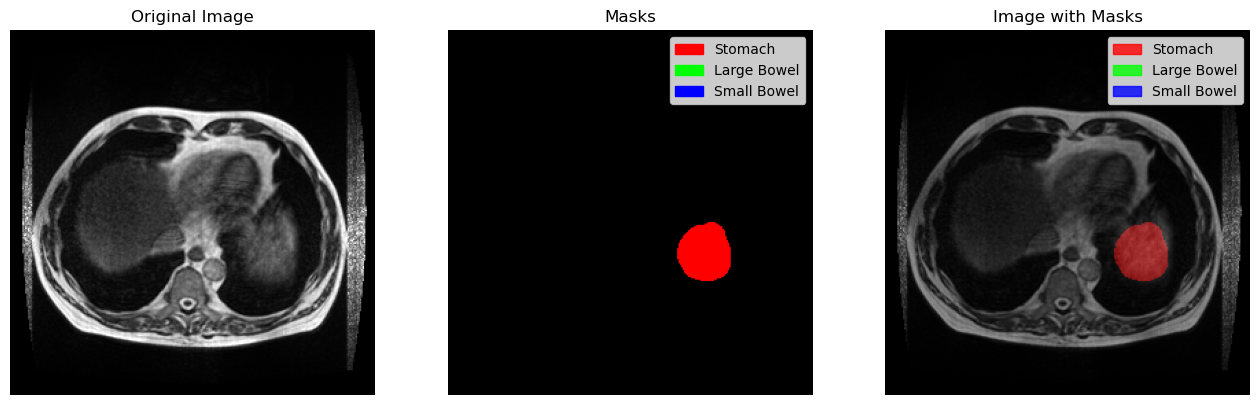

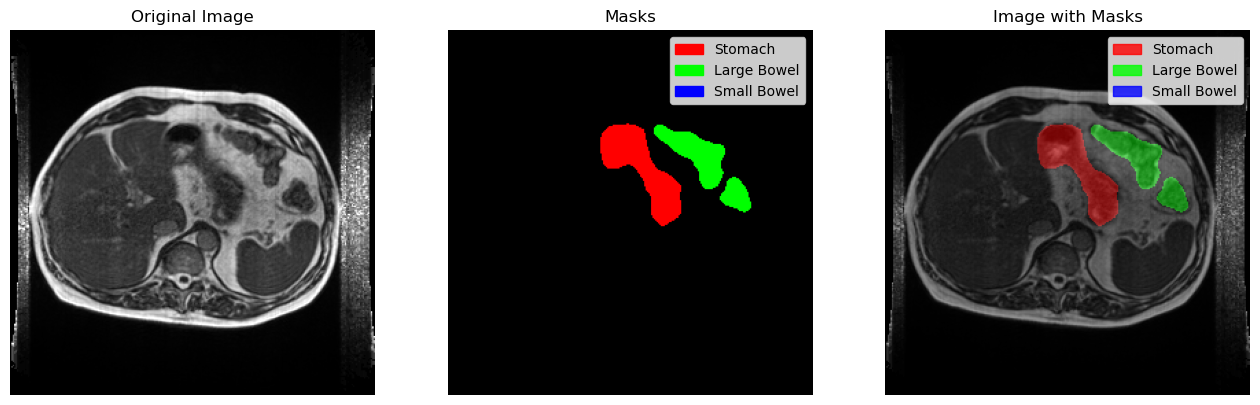

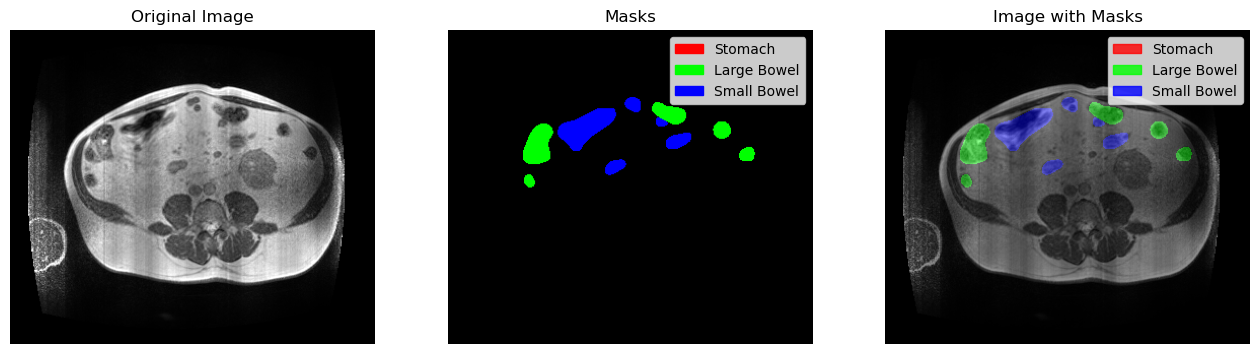

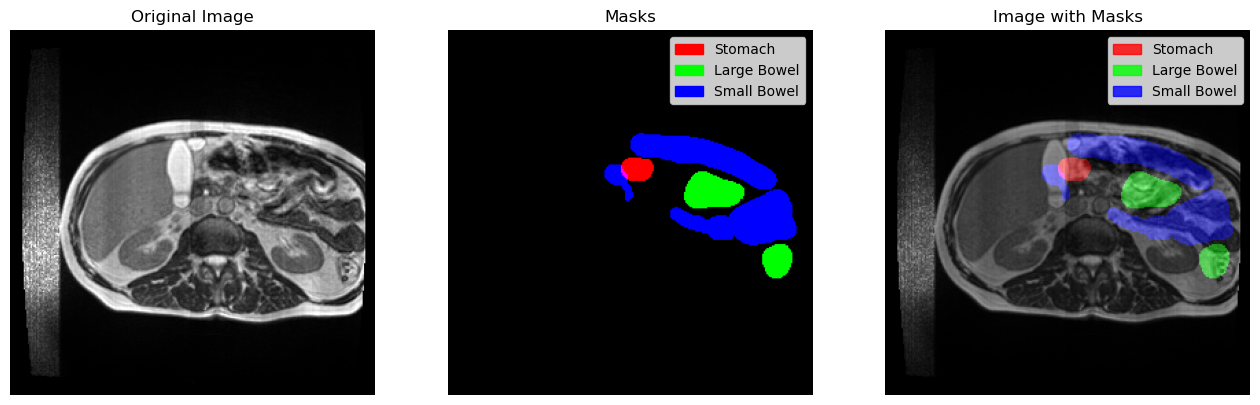

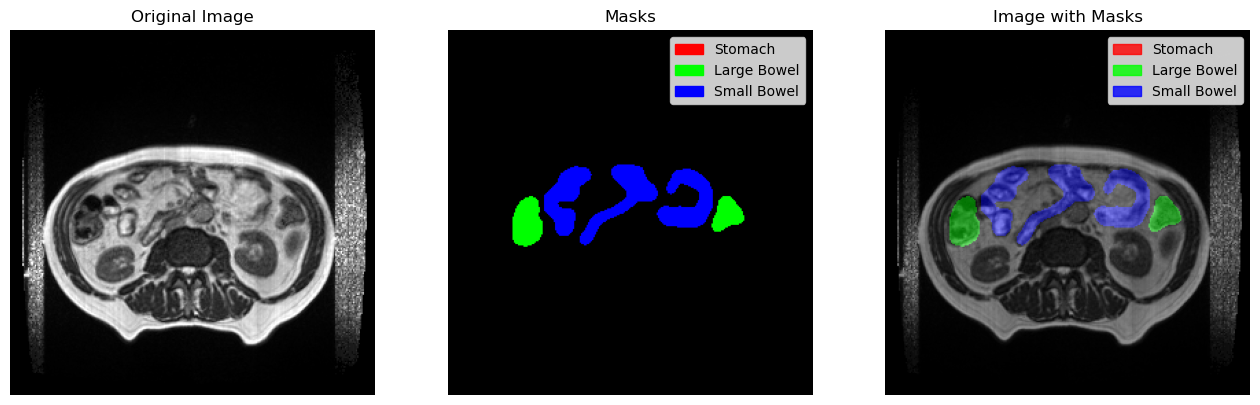

In [182]:
for i in range(0,10):
    show_image_with_mask(np.random.randint(0, len(train_df)), train_df)